In [2]:
import sys
sys.path.append("..")

import torch
import numpy as np
import matplotlib.pyplot as plt

from src.dataset import get_dataloaders
from src.model   import AlzheimerMILModel
from src.utils   import (
    compute_metrics, print_metrics,
    plot_confusion_matrix, plot_roc_curve,
    plot_attention_weights, load_checkpoint
)
from config import DEVICE, TEST_CSV

print("Setup complete")

Setup complete


In [4]:
model = AlzheimerMILModel().to(DEVICE)
epoch, val_metrics = load_checkpoint(model, filename="best_model.pt")

print(f"Best model from epoch : {epoch}")
print(f"Val AUC at checkpoint : {val_metrics['auc']}")

C:\Users\vaibh\anaconda3\envs\alzheimers\lib\site-packages\torch\nn\modules\module.py:1326: UserWarning: expandable_segments not supported on this platform (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\builder\windows\pytorch\c10/cuda/CUDAAllocatorConfig.h:28.)
  return t.to(
C:\Users\vaibh\Downloads\alzheimers_approach\notebooks\..\src\utils.py:79: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `tor

Loaded checkpoint from epoch 6 (AUC: 0.9208)
Best model from epoch : 6
Val AUC at checkpoint : 0.9208


In [5]:
_, _, test_loader = get_dataloaders()

model.eval()
all_labels  = []
all_probs   = []
all_weights = []
all_ids     = []

with torch.no_grad():
    for bags, labels, masks, ids in test_loader:
        bags  = bags.to(DEVICE)
        masks = masks.to(DEVICE)

        logits, weights = model(bags, masks)
        probs = torch.sigmoid(logits.squeeze(1)).cpu().numpy()

        all_probs.extend(probs.tolist())
        all_labels.extend(labels.numpy().tolist())
        all_weights.extend(weights.cpu().numpy().tolist())
        all_ids.extend(ids)

metrics = compute_metrics(all_labels, all_probs)
print_metrics(metrics, split="TEST")

Loaded 242 patients (0 skipped — fewer than 3 slices)
  Non-Demented : 186 patients
  Demented     : 56  patients
Loaded 52 patients (0 skipped — fewer than 3 slices)
  Non-Demented : 40 patients
  Demented     : 12  patients
Loaded 53 patients (0 skipped — fewer than 3 slices)
  Non-Demented : 40 patients
  Demented     : 13  patients

TEST Metrics:
  AUC         : 0.8788
  F1          : 0.6667
  Sensitivity : 0.7692  (recall for Demented)
  Specificity : 0.8250  (recall for Non-Demented)
  Accuracy    : 0.8113
  TP:10  TN:33  FP:7  FN:3


  [Saved] confusion matrix -> C:\Users\vaibh\Downloads\alzheimers_approach\outputs\confusion_matrix.png


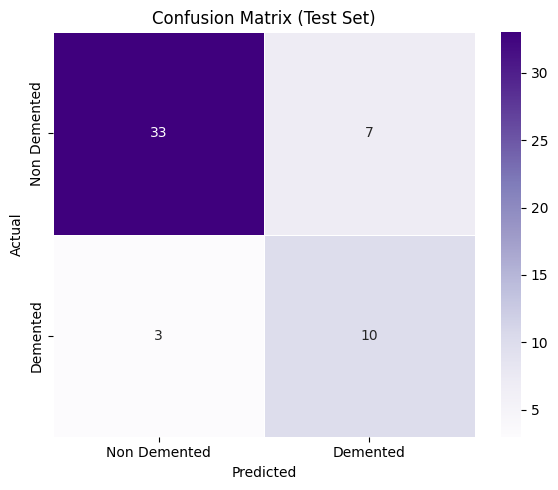

In [6]:
plot_confusion_matrix(all_labels, all_probs, threshold=0.5)

  [Saved] ROC curve -> C:\Users\vaibh\Downloads\alzheimers_approach\outputs\roc_curve.png


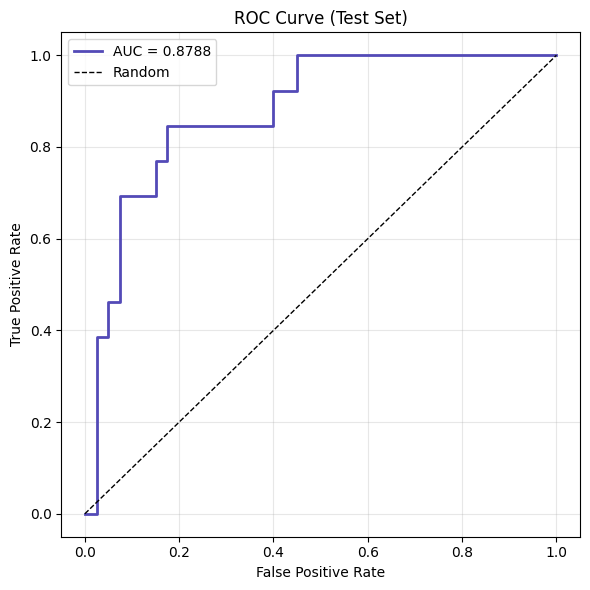

In [7]:
plot_roc_curve(all_labels, all_probs, metrics['auc'])

  [Saved] attention plot -> C:\Users\vaibh\Downloads\alzheimers_approach\outputs\attention_OAS1_0003.png


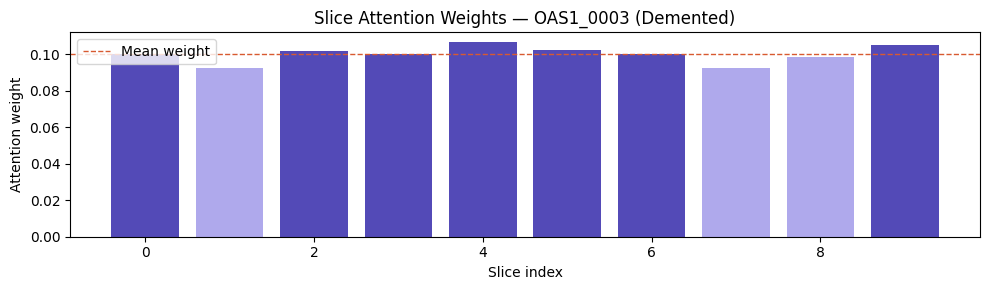

In [8]:
# find a demented patient and visualize which slices the model focused on
for i, (pid, label) in enumerate(zip(all_ids, all_labels)):
    if label == 1:   # demented patient
        w = torch.tensor(all_weights[i])
        plot_attention_weights(w, pid, label=1)
        break